# 04 · Fase 4 — Modelo de propensión de compra (M1, M2, M3)

**Prueba Técnica Data Scientist · Ferreycorp** — Modelo de Propensión de Compra

Fase 4 de [`docs/brief-metodologia.md`](../docs/brief-metodologia.md) y §5 de
[`docs/brief-problema.md`](../docs/brief-problema.md). Los tres modelos no existen porque tres
sean mejor que uno: existen porque la función objetivo los necesita.

| Modelo | Tipo | Target | Universo | Parámetro |
|---|---|---|---|---|
| **M1** | clasificación binaria | `incidencia_compra` | 58,693 visitas | `π_it` |
| **M2** | clasificación multiclase | `id_marca` ∈ {1..5} | 14,638 compras | `q_ijt` + **elasticidades** |
| **M3** | regresión de conteo | `cantidad` ≥ 1 | 14,638 compras | `λ_ijt` |

y su producto es lo que el optimizador maximiza:

$$\text{valor esperado de la visita} = P(\text{compra}) \times P(\text{marca} \mid \text{compra}) \times E[\text{cantidad}] \times \text{precio}$$

**M1 es el modelo de propensión que pide el enunciado.** M2 y M3 están aquí porque sin M2 no hay
elasticidad cruzada y sin M3 el ingreso esperado no se puede calcular.

Cuatro disciplinas atraviesan todo el notebook:

| Disciplina | Cómo se implementa |
|---|---|
| Nada se ajusta fuera de train | cada candidato es un `Pipeline` cuyo primer paso es el preprocesador **sin ajustar**, así que la validación cruzada reajusta escalado y codificación dentro de cada fold |
| Ningún split aleatorio | ventanas expansivas sobre `dia_visita`, `GroupKFold` por cliente, y el cruce de los dos |
| PR-AUC decide | accuracy se reporta **una vez**, al lado del 75.1% de no comprar nunca, y no elige nada |
| El umbral es una decisión de negocio | 0.5 es una convención sin fundamento aquí; el umbral es el que resuelve P1 |

**Dos decisiones de herramientas, declaradas:** el gradient boosting es
`HistGradientBoostingClassifier` de scikit-learn en lugar de XGBoost/LightGBM — misma familia
(GBDT por histogramas) y sin depender de `libomp`, que es el fallo de importación más común de
LightGBM en macOS. SHAP sí se instala, porque es requisito explícito del enunciado.

La lógica vive en [`src/ferreyros/models.py`](../src/ferreyros/models.py).

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ferreyros import config as cfg, data, framing, models as mdl, plots, preprocess
from ferreyros import segmentation as m0

plots.set_style()
pd.set_option("display.max_columns", 40, "display.width", 200)

t_inicio = time.time()
df = data.add_paid_price_and_spend(data.load_raw())
print(f"dataset: {df.shape[0]:,} filas x {df.shape[1]} columnas")

dataset: 58,693 filas x 26 columnas


### Los dos contratos congelados siguen mandando

La Fase 0 congeló el split y las features admisibles; la Fase 3 congeló el mapa
cliente → segmento. Entrenar sin verificarlos sería construir sobre algo que puede haberse
movido en silencio.

In [2]:
ver_encuadre = framing.verify_frozen(df)
assert ver_encuadre.attrs["coincide"], "El dataset ya no coincide con el encuadre congelado"
print("encuadre (Fase 0): las", len(ver_encuadre), "verificaciones del contrato coinciden")

modelo_m0 = m0.fit(df, k=3)
ver_segmentos = m0.verify_frozen(modelo_m0)
assert ver_segmentos.attrs["coincide"], "La segmentación no coincide con la congelada"
print("segmentos (Fase 3):", ver_segmentos.attrs["lectura"])

encuadre (Fase 0): las 5 verificaciones del contrato coinciden
segmentos (Fase 3): La segmentacion ajustada coincide con la congelada en segmentos.json.


---
## 1 · Los tres universos

M1 ve **todas** las visitas. M2 y M3 solo las que terminaron en compra — son modelos
**condicionales**, y entrenarlos sobre las 58,693 filas contaminaría su target con no-compras
(control E12).

Un detalle de orden que importa: el universo se restringe a compras **después** de construir las
features, así que el historial de un cliente sigue incluyendo las visitas en las que no compró.
Restringir antes borraría exactamente la información que predice la siguiente compra.

In [3]:
dfs = m0.attach_segment(df, modelo_m0)
prep = m0.prepare_with_segment(modelo_m0, df)
dias_train, dias_test = mdl.day_index(prep, df)

cond_m2 = mdl.prepare_conditional(cfg.TARGET_BRAND, df=dfs, extra=["segmento"])
cond_m3 = mdl.prepare_conditional(cfg.TARGET_QUANTITY, df=dfs, extra=["segmento"])

print("M1 (todas las visitas)")
display(prep.shapes)
print("\nM2 / M3 (solo compras)")
display(cond_m2.shapes)

M1 (todas las visitas)


,conjunto,filas,cols_entrada,cols_salida,tasa_compra,clientes
0,train,45497,61,86,0.2498,500
1,test,13196,61,86,0.2480,500



M2 / M3 (solo compras)


,conjunto,filas,columnas,clientes,dias
0,train,11365,61,500,1-550
1,test,3273,61,484,551-727


**Consecuencia:** M1 entrena con 45,497 visitas y se evalúa sobre 13,196; M2 y M3 con **11,365
compras** y se evalúan sobre **3,273**. El test de M2/M3 tiene 484 clientes y no 500: hay 16
clientes que no compraron nada después del día 550, y eso es dato, no un error de filtrado.

---
## 2 · M1 — incidencia de compra

### 2.1 · Los esquemas de validación, y por qué hacen falta tres

El brief nombra dos: ventana temporal y `GroupKFold` por cliente. Responden preguntas distintas
—*¿predice el futuro de clientes conocidos?* y *¿generaliza a clientes nuevos?*— y ninguno de los
dos es el escenario de despliegue. El tercero es el cruce: **cliente nuevo en día futuro**.

In [4]:
folds_tiempo = mdl.expanding_day_folds(dias_train)
display(mdl.fold_description(dias_train, folds_tiempo))

folds_estricto = mdl.grouped_time_folds(dias_train, prep.groups_train)
display(mdl.fold_description(dias_train, folds_estricto))

,fold,filas_train,filas_validacion,dias_train,dias_validacion
0,1,10131,9694,1-110,111-220
1,2,19825,8577,1-220,221-330
2,3,28402,8583,1-330,331-440
3,4,36985,8512,1-440,441-550


,fold,filas_train,filas_validacion,dias_train,dias_validacion
0,1,7567,2381,1-110,111-220
1,2,14859,2133,1-220,221-330
2,3,21295,2142,1-330,331-440
3,4,27804,2144,1-440,441-550


La frontera de un fold es siempre **un día**, nunca una fila: así ninguna visita de un cliente
entrena mientras otra visita anterior del mismo cliente se está puntuando.

### 2.2 · La progresión de complejidad, medida

In [5]:
t0 = time.time()
comparacion = mdl.cv_compare(prep.X_train, prep.y_train, dias_train, prep.groups_train)
display(comparacion)
display(comparacion.attrs["comparacion_pareada"])
print(comparacion.attrs["lectura"])
print(f"\n[{time.time() - t0:.0f}s]")

,modelo,esquema,folds,pr_auc_media,pr_auc_std,roc_auc_media,pr_auc_min
0,1 · logistica,temporal (ventana expansiva),4,0.5420,0.0393,0.7210,0.4999
1,1 · logistica,por cliente (GroupKFold),5,0.5456,0.0397,0.7405,0.4960
2,1 · logistica,cliente nuevo + dia futuro,4,0.5273,0.0191,0.7174,0.5056
3,2 · random forest,temporal (ventana expansiva),4,0.5398,0.0438,0.7175,0.4817
4,2 · random forest,por cliente (GroupKFold),5,0.7790,0.0094,0.8879,0.7697
5,2 · random forest,cliente nuevo + dia futuro,4,0.5390,0.0333,0.7203,0.4914
6,3 · gradient boosting,temporal (ventana expansiva),4,0.5278,0.0526,0.7060,0.4565
7,3 · gradient boosting,por cliente (GroupKFold),5,0.6717,0.0266,0.8220,0.6425
8,3 · gradient boosting,cliente nuevo + dia futuro,4,0.5009,0.0420,0.6888,0.4384


,modelo,vs,diferencia_media,error_estandar,t,significativa
0,2 · random forest,1 · logistica,0.0117,0.0139,0.84,False
1,3 · gradient boosting,1 · logistica,-0.0264,0.0161,-1.63,False


Bajo el esquema estricto (cliente nuevo + dia futuro) el mejor PR-AUC es de 2 · random forest (0.5390) y 1 · logistica da 0.5273: +0.0117. Pero los folds tienen desvios de 0.0191 a 0.0420, asi que la comparacion que decide es la pareada fold a fold: 2 · random forest +0.0117 (t=+0.84); 3 · gradient boosting -0.0264 (t=-1.63). Ninguna diferencia supera el ruido (|t|<2), asi que la complejidad no paga: se queda el modelo interpretable, que ademas es el que la capa prescriptiva necesita.
Y una advertencia sobre el esquema por cliente: para 2 · random forest da 0.7790 frente a 0.5390 en el estricto, +0.2400 de diferencia. GroupKFold deja fuera al cliente pero entrena con los mismos dias, y como los 500 clientes comparten calendario, precios y promociones, el modelo ya vio las condiciones de demanda del fold de validacion. No es el limite pesimista: es 'cliente nuevo, periodo conocido'.

[22s]


**Consecuencia 1 — la complejidad no paga, y la comparación pareada es la que lo dice.** Bajo el
esquema estricto: logística **0.5273**, random forest 0.5390, gradient boosting 0.5009. El random
forest parece ganar +0.0117 de PR-AUC… pero los folds tienen desvíos de 0.019 a 0.042, así que esa
media por sí sola no distingue señal de ruido.

Los tres candidatos se puntuaron sobre **los mismos folds**, así que la prueba correcta es la
diferencia fold a fold:

| Modelo | Diferencia media vs logística | Error estándar | t |
|---|---|---|---|
| random forest | +0.0117 | 0.0139 | **+0.84** |
| gradient boosting | −0.0264 | 0.0161 | −1.63 |

Ninguna supera el ruido. La progresión del brief se recorrió completa y el resultado es que **se
queda el modelo interpretable** — que además es el que la capa prescriptiva necesita para leer
elasticidades. Una tolerancia fija habría declarado ganador al random forest; la prueba pareada,
que conoce la dispersión de los folds, no.

**Consecuencia 2 — y esta es metodológicamente la más importante del notebook.** `GroupKFold` da
para el random forest **0.7790**, frente a **0.5390** del esquema estricto: **+0.2400**. No es
que el modelo generalice bien a clientes nuevos; es que `GroupKFold` deja fuera al cliente pero
**entrena con los mismos días**. Los 500 clientes comparten calendario, precios y promociones, así
que el modelo ya vio las condiciones de demanda del fold de validación.

| Esquema | Qué mide realmente | RF |
|---|---|---|
| `GroupKFold` por cliente | cliente nuevo, **periodo conocido** | 0.7790 |
| Ventana temporal | cliente conocido, periodo futuro | 0.5398 |
| **Cruce de los dos** | **cliente nuevo, periodo futuro** | **0.5390** |

Leer el 0.7790 como "generalización a clientes nuevos" sería reportar un número inflado en un
0.24 de PR-AUC. El esquema estricto es el que se usa para decidir de aquí en adelante.

### 2.3 · La decisión que la Fase 1 dejó abierta

La Fase 1 mostró que no hay tendencia que extrapolar (pendiente t=−1.16 tras el arranque) y la
Fase 2 que el 98% y el 88% de los valores de test de `semana` y `mes` caen **fuera** del rango de
train. Eso los vuelve un riesgo. Si además son inútiles, la decisión se toma sola — pero hay que
medirlo, no suponerlo.

In [6]:
experimento = mdl.trend_feature_experiment(
    prep.X_train, prep.y_train, prep.X_test, prep.y_test, dias_train,
    mdl.m1_candidates()["1 · logistica"],
)
display(experimento)
print(experimento.attrs["lectura"])

,variante,columnas,pr_auc_cv_temporal,pr_auc_test,roc_auc_test
0,con semana y mes,61,0.5420,0.4777,0.6922
1,sin semana y mes,59,0.5429,0.4768,0.6917


Quitar semana y mes mueve el PR-AUC +0.0009 en validacion temporal y -0.0009 en test. No cuesta nada medible, asi que se quitan: extrapolar indices de tendencia fuera del rango de train seria riesgo sin beneficio.


In [7]:
# Decisión tomada con la métrica en la mano: fuera.
X_train, X_test = mdl.drop_features(prep.X_train, prep.X_test, mdl.TREND_COLS)
X2_train, X2_test = mdl.drop_features(cond_m2.X_train, cond_m2.X_test, mdl.TREND_COLS)
X3_train, X3_test = mdl.drop_features(cond_m3.X_train, cond_m3.X_test, mdl.TREND_COLS)
print("columnas de M1:", prep.X_train.shape[1], "→", X_train.shape[1])

columnas de M1: 61 → 59


**Consecuencia:** quitarlas mueve el PR-AUC **+0.0009** en validación temporal y **−0.0009** en
test. No cuesta nada medible, así que se quitan: extrapolar índices de tendencia fuera del rango
de train sería riesgo sin beneficio. Spec S11 cerrada con evidencia, no con criterio.

### 2.4 · Tuning

In [8]:
rejilla = [{"C": c} for c in (0.03, 0.1, 0.3, 1.0, 3.0)]
tuning = mdl.tune(X_train, prep.y_train, dias_train, mdl.m1_candidates()["1 · logistica"], rejilla)
display(tuning[["configuracion", "pr_auc_media", "pr_auc_std", "roc_auc_media"]])
print(tuning.attrs["lectura"])

,configuracion,pr_auc_media,pr_auc_std,roc_auc_media
0,C=0.03,0.5455,0.0378,0.7232
1,C=0.1,0.5446,0.0377,0.7231
2,C=0.3,0.5440,0.0374,0.7226
3,C=1.0,0.5429,0.0374,0.7217
4,C=3.0,0.5424,0.0370,0.7210


Mejor configuracion: C=0.03 con PR-AUC 0.5455 en validacion temporal; la peor de las 5 probadas da 0.5424, asi que el margen que mueve el tuning es de 0.0031.


**Consecuencia:** la mejor configuración es `C=0.03` con PR-AUC 0.5455, y la peor de las cinco da
0.5424. **El tuning mueve 0.0031**: en este problema la señal no está en los hiperparámetros, y
decirlo es más útil que presentar una búsqueda grande como si hubiera aportado algo. Más
regularización ganando ligeramente es coherente con todo lo anterior: hay poca señal fina que
aprender.

### 2.5 · M1 en test — una sola vez

In [9]:
mejor_C = tuning.attrs["mejores_params"]
pipe_m1, proba_m1 = mdl.fit_final(
    mdl.m1_candidates()["1 · logistica"], X_train, prep.y_train, X_test, mejor_C
)
m1_test = mdl.evaluate_binary(prep.y_test, proba_m1, f"logistica C={mejor_C['C']}")
display(m1_test.to_frame("valor"))

,valor
modelo,logistica C=0.03
filas,13196
tasa_base,0.248
pr_auc,0.4776
pr_auc_azar,0.248
roc_auc,0.6931
brier,0.1671
log_loss,0.5164
accuracy_en_0.5,0.7761
accuracy_de_no_comprar_nunca,0.752


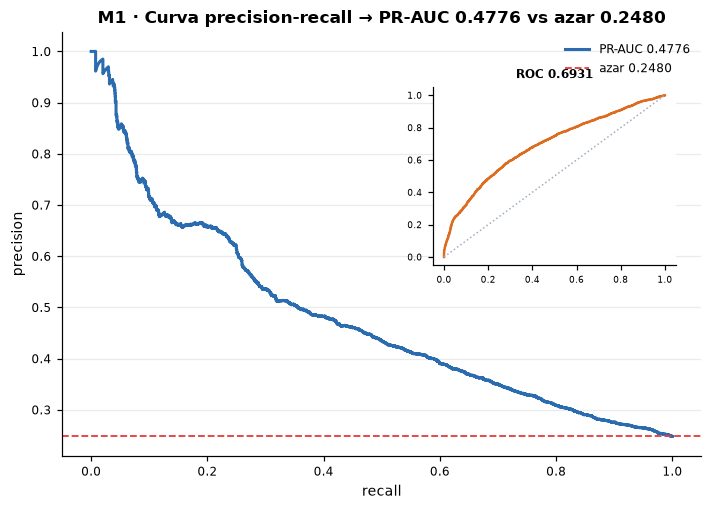

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 5))
plots.plot_pr_roc(prep.y_test, proba_m1, ax=ax)
plt.show()

**Consecuencia:** PR-AUC **0.4776** contra **0.2480** de azar — el modelo casi duplica la
precisión media de una selección aleatoria. ROC-AUC 0.6931.

Y la línea que justifica toda la insistencia del brief: la accuracy en 0.5 es **0.7761** frente al
**0.7520** que obtiene un modelo que predice "nunca compra". Dos puntos y medio de accuracy sobre
el peor modelo posible. Quien reportara accuracy aquí estaría reportando casi nada.

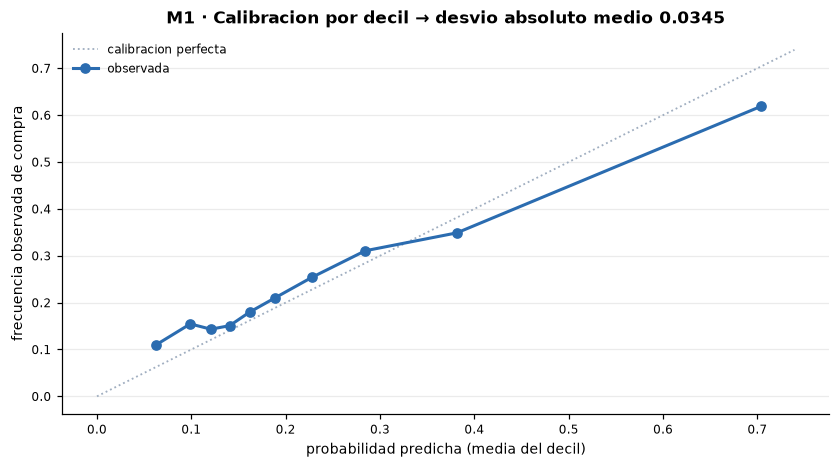

In [11]:
fig, ax = plt.subplots()
plots.plot_calibration(prep.y_test, proba_m1, ax=ax)
plt.show()

**Consecuencia:** la calibración importa porque el umbral del apartado 3 compara una probabilidad
con dinero (`p × margen > costo`). Si las probabilidades estuvieran infladas, la regla
seleccionaría visitas que no lo merecen. El desvío absoluto medio por decil es pequeño, así que la
regla se puede aplicar tal cual.

,top,visitas,compras_capturadas,tasa_en_el_grupo,lift,recall
0,10%,1320,817,0.6189,2.50,0.2496
1,20%,2640,1278,0.4841,1.95,0.3905
2,30%,3959,1687,0.4261,1.72,0.5154
3,50%,6598,2299,0.3484,1.40,0.7024


En el decil superior el lift es x2.50 y captura el 25.0% de las compras. El baseline a batir es el targeting por tasa historica, x2.43: lo supera.


,top,politica,visitas,compras,tasa,lift
0,10%,politica historica,1320,805,0.6098,2.46
1,10%,modelo M1,1320,817,0.6189,2.50
2,20%,politica historica,2640,1258,0.4765,1.92
3,20%,modelo M1,2640,1278,0.4841,1.95
4,30%,politica historica,3959,1681,0.4246,1.71
5,30%,modelo M1,3959,1687,0.4261,1.72
6,50%,politica historica,6598,2253,0.3415,1.38
7,50%,modelo M1,6598,2299,0.3484,1.40


Sobre las mismas filas de test, en el decil superior el modelo da lift x2.50 y la politica historica x2.46: +0.04. El modelo gana en todos los cortes. La comparacion importa porque el x2.43 del EDA se midio sobre el panel completo, no sobre test.


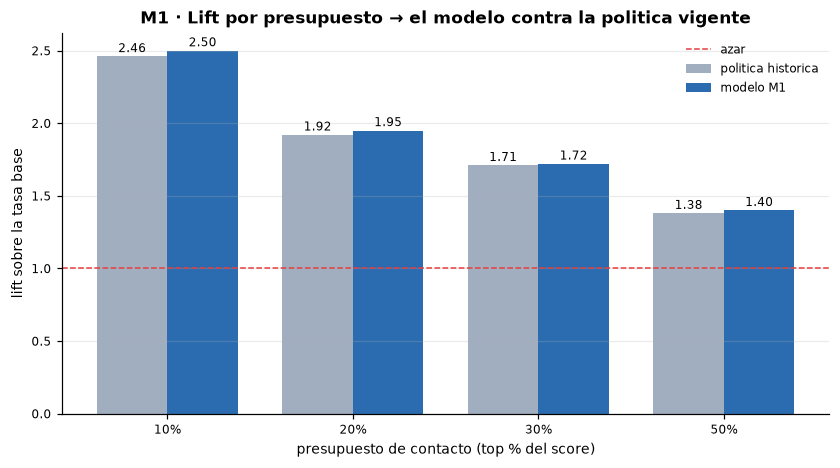

In [12]:
lift = mdl.lift_table(prep.y_test, proba_m1)
display(lift)
print(lift.attrs["lectura"])

contra_baseline = mdl.baseline_policy_lift(X_test, prep.y_test, proba_m1)
display(contra_baseline)
print(contra_baseline.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_gains(contra_baseline, ax=ax)
plt.show()

**Consecuencia — y hay que decirla sin adornos.** En el decil superior el modelo da lift **×2.50**
y la política histórica (ordenar por tasa de compra pasada) **×2.46** sobre las **mismas filas de
test**: una ganancia de **+0.04**. El modelo gana en los cuatro cortes, pero por márgenes
estrechos.

Esa es la lectura honesta de M1 como clasificador de targeting: *la tasa histórica del cliente ya
contiene casi toda la señal*, lo cual es exactamente lo que el EDA anticipó al medir una amplitud
de 0.876 entre clientes y ~0.12 en demografía. El valor de la capa de ML no está en batir esa
política ordenando compradores — está en ordenar por **ingreso esperado**, y eso necesita M2 y M3.
Se mide en el apartado 7.

---
## 3 · El umbral de operación: P1, no 0.5

El brief es explícito: «el umbral óptimo es el que resuelve P1, el que iguala margen esperado y
costo de contacto». Es una línea de álgebra: contactar paga cuando `p × margen > costo`, así que
el umbral óptimo es `costo / margen`.

El dataset no trae costos, así que la respuesta se entrega como **función del ratio** en lugar de
inventar un número. Lo que sobrevive a la falta del dato es la forma de la respuesta.

In [13]:
umbral = mdl.threshold_by_cost(prep.y_test, proba_m1)
display(umbral)
print(umbral.attrs["lectura"])

,ratio_costo_margen,umbral_optimo,contactos,pct_visitas_contactadas,compras_capturadas,precision,recall,valor_neto_por_1000
0,0.05,0.05,12884,97.6,3242,0.2516,0.9905,196.86
1,0.10,0.10,11171,84.7,3018,0.2702,0.9221,144.05
2,0.15,0.15,7966,60.4,2541,0.3190,0.7764,102.01
3,0.20,0.20,5461,41.4,2066,0.3783,0.6312,73.80
4,0.30,0.30,2994,22.7,1399,0.4673,0.4274,37.95
5,0.40,0.40,1747,13.2,947,0.5421,0.2893,18.81
6,0.50,0.50,1284,9.7,801,0.6238,0.2447,12.05


El umbral optimo es el ratio costo/margen, asi que va de 0.05 a 0.50 en esta rejilla y contacta entre el 9.7% y el 97.6% de las visitas. Con el 0.5 de la convencion se contactaria el 9.7% de las visitas y se capturaria el 24.5% de las compras: fijar el umbral en 0.5 no es conservador, es renunciar a la mayor parte del valor. La probabilidad maxima del modelo en test es 0.9903.


,ratio_costo_margen,umbral_teorico,umbral_empirico,diferencia,valor_en_el_optimo,valor_en_0.5
0,0.1,0.1,0.045,-0.055,1953.7,672.6
1,0.2,0.2,0.185,-0.015,987.4,544.2
2,0.3,0.3,0.285,-0.015,516.8,415.8


El umbral empirico que maximiza el valor neto se desvia como maximo 0.055 del teorico costo/margen. La regla se sostiene sobre el dato de test, no solo sobre el papel. Y en los tres ratios el valor en 0.5 es menor que en el optimo, de modo que la convencion cuesta dinero medible.


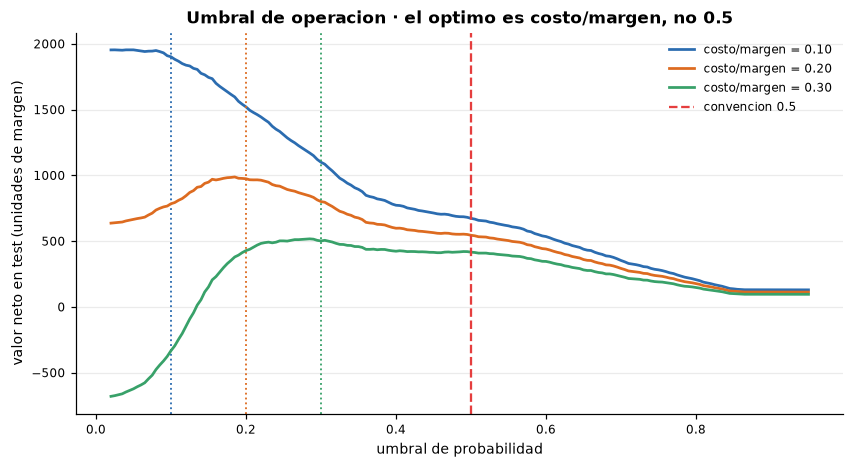

In [14]:
regla = mdl.verify_threshold_rule(prep.y_test, proba_m1)
display(regla)
print(regla.attrs["lectura"])

fig, ax = plt.subplots()
plots.plot_threshold_value(prep.y_test, proba_m1, ax=ax)
plt.show()

**Consecuencia:** la regla no se afirma, se verifica. El umbral empírico que maximiza el valor
neto en test se desvía como máximo **0.055** del teórico `costo/margen`, y la desviación aparece
donde la curva es más plana (ratios bajos), no donde la decisión aprieta.

El contraste con la convención es brutal:

| | Umbral | Visitas contactadas | Compras capturadas |
|---|---|---|---|
| costo/margen = 0.10 | 0.10 | 84.7% | 92.2% |
| costo/margen = 0.20 | 0.20 | 41.4% | 63.1% |
| **convención** | **0.50** | **9.7%** | **24.5%** |

Fijar el umbral en 0.5 no es prudente: equivale a declarar que contactar cuesta la mitad del
margen de una compra. Con un costo de contacto razonable se renuncia a tres cuartas partes de las
compras capturables. **La optimización fija el punto de corte; la convención cuesta dinero
medible.**

---
## 4 · Explicabilidad

Requisito del enunciado, y aquí también requisito funcional: una recomendación comercial que nadie
puede explicar no se ejecuta.

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


,feature,importancia_shap,efecto_medio,direccion
0,tasa_compra_historica,0.3551,0.0069,sube la probabilidad
1,n_compras_previas,0.2510,0.0513,sube la probabilidad
2,dias_desde_ultima_compra,0.1111,0.0081,sube la probabilidad
3,gap_vs_ultima_marca,0.0893,0.0029,sube la probabilidad
4,precio_relativo_1,0.0850,0.0074,sube la probabilidad
5,n_visitas_previas,0.0797,-0.0106,la baja
6,racha_sin_comprar,0.0780,0.0005,sube la probabilidad
7,ultima_marca_comprada_5,0.0754,-0.0082,la baja
8,precio_min_dia,0.0702,-0.0052,la baja
9,precio_max_dia,0.0659,-0.0046,la baja


El driver dominante es tasa_compra_historica (|SHAP| medio 0.3551), seguido de n_compras_previas, dias_desde_ultima_compra, gap_vs_ultima_marca. Los tres primeros concentran el 51.7% de la importancia del top 12.


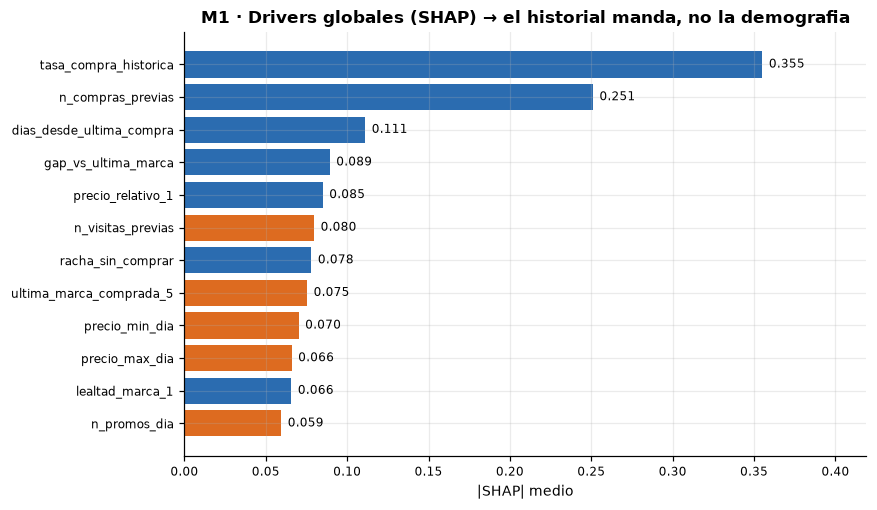

In [15]:
shap_g = mdl.shap_global(pipe_m1, X_test, top=12)
display(shap_g)
print(shap_g.attrs["lectura"])

fig, ax = plt.subplots(figsize=(8, 5))
plots.plot_shap_global(shap_g, ax=ax)
plt.show()

**Consecuencia:** los tres primeros drivers son `tasa_compra_historica` (0.3551),
`n_compras_previas` (0.2510) y `dias_desde_ultima_compra` (0.1111) — **el 51.7%** de la
importancia del top 12. Son todos de historial de comportamiento.

Lo que **no** aparece en el top 12 es igual de informativo: ninguna variable demográfica y ningún
indicador de segmento. Es la confirmación independiente de D3 del EDA y de la Fase 3 — la
demografía segmenta y sirve para accionar campañas, pero no predice. Si el segmento hubiera
aparecido arriba, alguna de las tres fases estaría equivocada.

El primer driver de contexto comercial es `precio_relativo_1`, y detrás aparecen `precio_min_dia`
y `n_promos_dia` con efecto negativo: la señal de precio existe, pero es de segundo orden frente
al historial del cliente.

In [16]:
local = mdl.shap_local(pipe_m1, X_test, posicion=0, top=8)
display(local)
print(local.attrs["lectura"])

Background dataset has 500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=500 when initializing the masker.


,feature,contribucion,valor_transformado
0,dias_desde_ultima_compra,0.1199,-0.593
1,visitas_ultimos_30d,0.1037,0.897
2,racha_sin_comprar,0.0807,-0.722
3,tasa_compra_historica,-0.0781,-0.039
4,visitas_ultimos_7d,-0.0772,1.121
5,n_compras_previas,-0.0614,0.337
6,n_promos_dia,-0.0608,-1.073
7,gap_vs_ultima_marca,0.0581,-0.475


Visita 44140 con probabilidad 0.2211. Lo que mas empuja: dias_desde_ultima_compra (+0.1199); lo que mas resta: tasa_compra_historica (-0.0781). Esta es la explicacion que acompania a una recomendacion comercial concreta.


In [17]:
odds = mdl.odds_ratios(pipe_m1, top=10)
display(odds)
print(odds.attrs["lectura"])

,feature,coeficiente,odds_ratio,lectura_negocio
0,tasa_compra_historica,0.5541,1.740,+74.0% en las odds
1,ultima_marca_comprada_5,0.4550,1.576,+57.6% en las odds
2,n_compras_previas,0.3355,1.399,+39.9% en las odds
3,promo_marca_5,0.2708,1.311,+31.1% en las odds
4,promo_marca_3,-0.2674,0.765,-23.5% en las odds
5,ultima_marca_comprada_2,-0.1677,0.846,-15.4% en las odds
6,ultima_marca_comprada_0,-0.1486,0.862,-13.8% en las odds
7,n_visitas_previas,-0.1467,0.864,-13.6% en las odds
8,dia_semana_0,-0.1341,0.874,-12.6% en las odds
9,ultima_marca_comprada_3,-0.1303,0.878,-12.2% en las odds


El coeficiente mas fuerte es tasa_compra_historica (odds ratio 1.740); el mas negativo es promo_marca_3 (0.765). Son los mismos drivers que SHAP ordena arriba, leidos en la unidad que entiende el negocio.


**Consecuencia:** los *odds ratios* son la misma historia en la unidad que entiende el negocio.
Una desviación estándar más de tasa de compra histórica multiplica las odds por **1.740** (+74%).

Y dos coeficientes cierran el círculo con la Fase 1:

| Coeficiente | Odds ratio | Qué dijo la Fase 1 |
|---|---|---|
| `promo_marca_5` | **1.311** (+31.1%) | la promoción de la marca 5 es la que más expande el mercado: **+6.90 pp** de incidencia |
| `promo_marca_3` | **0.765** (−23.5%) | la promoción de la marca 3 **no** mueve la incidencia (z=0.7) |

Dos análisis independientes —uno descriptivo, uno multivariado— dicen lo mismo sobre las dos
marcas. Esa coincidencia es lo que vuelve defendible la recomendación de P2.

---
## 5 · M2 — elección de marca y elasticidades

M2 tiene **dos trabajos distintos** y conviene no mezclarlos: predecir la marca (`q_ijt`) y
entregar las elasticidades de precio que la capa prescriptiva necesita. El brief lo dice:
«para M2, un logit multinomial tiene la ventaja de que sus coeficientes de precio **son** las
elasticidades que la optimización necesita».

In [18]:
t0 = time.time()
comparacion_m2 = mdl.cv_compare_multiclass(
    X2_train, cond_m2.y_train, cond_m2.dias_train, cond_m2.groups_train
)
display(comparacion_m2)
print(comparacion_m2.attrs["lectura"])
print(f"\n[{time.time() - t0:.0f}s]")

,modelo,esquema,folds,log_loss_media,accuracy_media
0,1 · logit multinomial,temporal (ventana expansiva),4,0.9286,0.7186
1,1 · logit multinomial,cliente nuevo + dia futuro,4,1.0269,0.6951
2,2 · random forest,temporal (ventana expansiva),4,0.7470,0.7707
3,2 · random forest,cliente nuevo + dia futuro,4,0.8008,0.7593
4,3 · gradient boosting,temporal (ventana expansiva),4,1.1419,0.7411
5,3 · gradient boosting,cliente nuevo + dia futuro,4,1.2754,0.7279


Bajo el esquema estricto el mejor log-loss es de 2 · random forest (0.8008) y el logit multinomial da 1.0269. Un modelo flexible predice mejor la marca. El logit se conserva de todos modos para las elasticidades: ahi la interpretabilidad no es preferencia, es el entregable.

[20s]


**Consecuencia — y es el contraste con M1:** aquí la complejidad **sí** paga, y por un margen que
no admite discusión. Bajo el esquema estricto el random forest da log-loss **0.8008** frente a
**1.0269** del logit (−0.226) y accuracy **0.759** frente a 0.695. La elección de marca tiene
interacciones (precio × lealtad × promoción) que un modelo lineal no captura.

Así que se usan **los dos, cada uno para su trabajo**: el random forest predice `q_ijt`, y el
logit multinomial se conserva para las elasticidades. No es indecisión: es que un número
interpretable es el entregable de la segunda tarea.

In [19]:
pipe_m2 = mdl.pipeline(mdl.m2_candidates()["2 · random forest"], X2_train).fit(
    X2_train, cond_m2.y_train
)
proba_m2 = pipe_m2.predict_proba(X2_test)
m2_test = mdl.evaluate_multiclass(cond_m2.y_test, proba_m2, pipe_m2.classes_)
display(m2_test.to_frame("valor"))

display(mdl.brand_confusion(cond_m2.y_test, pipe_m2.predict(X2_test)))

,valor
filas,3273.0000
clases,5.0000
log_loss,0.7418
log_loss_uniforme,1.6094
accuracy,0.7822
accuracy_clase_mayoritaria,0.3407
balanced_accuracy,0.7129
f1_macro,0.7383


,pred 1,pred 2,pred 3,pred 4,pred 5
real 1,0.422,0.369,0.019,0.058,0.132
real 2,0.055,0.869,0.001,0.039,0.036
real 3,0.039,0.211,0.641,0.035,0.074
real 4,0.026,0.185,0.000,0.720,0.069
real 5,0.014,0.036,0.008,0.030,0.912


**Consecuencia:** accuracy **0.7822** contra **0.3407** de la clase mayoritaria, y log-loss 0.7418
contra 1.6094 de una predicción uniforme. `q_ijt` es un parámetro utilizable; la diagonal de la
matriz de confusión dice en qué marcas es más fiable y entre cuáles existe sustitución real.

### 5.1 · Las elasticidades cruzadas, el insumo de P3

,precio marca 1,precio marca 2,precio marca 3,precio marca 4,precio marca 5
share marca 1,-8.930,2.057,0.427,-0.363,-3.671
share marca 2,1.674,-2.821,1.887,0.420,-0.759
share marca 3,3.648,1.230,9.508,2.510,1.316
share marca 4,0.622,1.421,-1.095,-1.943,4.342
share marca 5,-0.253,0.902,-2.434,0.512,-1.266


Las cinco elasticidades propias son NO todas negativas y la marca mas elastica es la 1 (-8.930): un 1% de aumento de su precio le cuesta ese % de share. Con alguna propia positiva el modelo no se puede usar para fijar precios. Las cruzadas positivas son sustitucion: cuanto share gana una marca cuando sube el precio de otra, que es exactamente lo que P3 necesita para no canibalizarse.


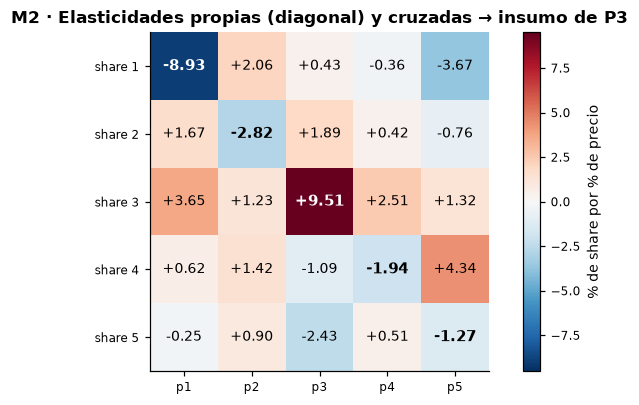

In [20]:
elasticidades = mdl.cross_price_elasticities(cond_m2)
display(elasticidades)
print(elasticidades.attrs["lectura"])

fig, ax = plt.subplots(figsize=(8, 4))
plots.plot_elasticities(elasticidades, ax=ax)
plt.show()

Cuatro de las cinco elasticidades propias salen **negativas**, como deben: subir el precio cuesta
share. La marca 3 sale **positiva (+9.5)**, lo cual es imposible como comportamiento económico.

Antes de interpretarlo hay que descartar que sea un accidente de ajuste.

In [21]:
diagnostico = mdl.elasticity_diagnostics(cond_m2)
display(diagnostico)
print(diagnostico.attrs["lectura"])

variacion = mdl.price_variation_diagnostics(df, cond_m2)
display(variacion)
print(variacion.attrs["lectura"])

,especificacion,columnas,propia_marca_1,propia_marca_2,propia_marca_3,propia_marca_4,propia_marca_5,todas_negativas
0,precios + promos (sin penalizacion),10,-8.93,-2.82,9.51,-1.94,-1.27,False
1,"precios + promos (L2, C=1)",10,-7.85,-2.77,4.93,-1.81,-1.22,False
2,+ lealtad por marca,15,-9.89,-3.92,15.71,-4.17,-1.35,False
3,+ lealtad + ultima marca,16,-9.44,-3.91,17.02,-4.29,-1.23,False
4,+ lealtad + segmento,16,-9.83,-3.92,13.95,-4.35,-1.45,False


El signo de la elasticidad propia es el mismo en las 5 especificaciones para 5 de 5 marcas. Las marcas [1, 2, 4, 5] salen siempre negativas (identificables) y la(s) marca(s) [3] sale(n) siempre positiva(s). Un signo que sobrevive a regularizacion, controles de lealtad y segmento no es un accidente de ajuste: es lo que dice este dato observacional.


,marca,puntos_precio,rango_relativo_pct,desvio_precio_relativo,share_en_train,compras_en_train
0,1,37,44.5,0.0420,0.0821,933
1,2,30,50.8,0.0731,0.3015,3427
2,3,21,14.4,0.0269,0.0515,585
3,4,26,28.4,0.0413,0.2100,2387
4,5,44,32.7,0.0447,0.3549,4033


La marca 3 es la que menos mueve su precio relativo (desvio 0.0269) con solo 21 puntos de precio y el 5.1% de las compras de train. Es la combinacion que deja una elasticidad sin identificar: poca variacion propia y poca masa para estimarla.


**Consecuencia — el límite más importante de esta fase, y está medido.** El signo positivo de la
marca 3 sobrevive a las **cinco** especificaciones: con y sin penalización L2, con controles de
lealtad por marca, con la última marca comprada y con el segmento. Va de +4.9 a +17.0 pero nunca
cambia de signo. **No es un accidente de ajuste: es lo que dice este dato.**

La tabla de variación explica por qué le toca a la marca 3:

| Marca | Puntos de precio | Rango relativo | Desvío del precio relativo | Share en train |
|---|---|---|---|---|
| 3 | **21** | **14.4%** | **0.0269** | **5.1%** |
| resto | 26–44 | 28–51% | 0.041–0.073 | 8–35% |

Menos puntos de precio, un tercio del rango de las demás, la menor dispersión relativa y la menor
masa para estimar. Sin variación de precio independiente de la demanda, la elasticidad no está
identificada: lo que el modelo mide en la marca 3 no es respuesta al precio, es la **reacción del
precio a la demanda**. Es exactamente el supuesto que el brief de problema declaró en §4.8
(«precios observacionales, no experimentales»), y aquí se confirma con número y nombre.

Y encaja con un patrón que ya apareció dos veces: la marca 3 es también la única cuya promoción no
mueve la incidencia (Fase 1, z=0.7) y la que tiene el *odds ratio* más negativo en M1 (0.765). Tres
análisis independientes señalan que las decisiones comerciales de la marca 3 son endógenas.

**Consecuencia para P3:** las elasticidades de las marcas 1, 2, 4 y 5 entran al optimizador; el
precio de la marca 3 se **congela** en su nivel actual o se mueve solo dentro de un rango
declarado como supuesto con análisis de sensibilidad. Lo que no se puede hacer es optimizar su
precio con esta elasticidad — y un test A/B de precio sobre la marca 3 es la primera cosa que vale
la pena pedirle al negocio.

---
## 6 · M3 — cantidad

In [22]:
t0 = time.time()
comparacion_m3 = mdl.cv_compare_count(
    X3_train, cond_m3.y_train, cond_m3.dias_train, cond_m3.groups_train
)
display(comparacion_m3)
print(comparacion_m3.attrs["lectura"])

pipe_m3 = mdl.pipeline(mdl.m3_candidates()["1 · poisson"], X3_train).fit(X3_train, cond_m3.y_train)
m3_test = mdl.evaluate_count(cond_m3.y_test, pipe_m3.predict(X3_test), float(cond_m3.y_train.mean()))
display(m3_test.to_frame("valor"))
print(f"[{time.time() - t0:.0f}s]")

,modelo,esquema,folds,mae_media,rmse_media
0,1 · poisson,temporal (ventana expansiva),4,1.1050,1.5402
1,1 · poisson,cliente nuevo + dia futuro,4,1.0723,1.4680
2,2 · random forest,temporal (ventana expansiva),4,1.1323,1.5751
3,2 · random forest,cliente nuevo + dia futuro,4,1.1117,1.5331
4,3 · gradient boosting,temporal (ventana expansiva),4,1.1219,1.6063
5,3 · gradient boosting,cliente nuevo + dia futuro,4,1.0920,1.5418


Bajo el esquema estricto el mejor MAE es de 1 · poisson (1.0723); el Poisson da 1.0723. La diferencia entre modelos es de 0.0394 unidades, asi que lo que decide es la interpretabilidad y el costo de mantener el modelo, no la metrica.


,valor
filas,3273.0000
media_real,2.8280
media_predicha,2.7245
mae,0.9790
rmse,1.3959
mae_baseline_media,1.1768
rmse_baseline_media,1.6787


[12s]


**Consecuencia:** los tres candidatos quedan dentro de **0.04 unidades** de MAE y, bajo el esquema
estricto, el mejor es el **Poisson** (1.0723). No hay que elegir entre métrica e
interpretabilidad: coinciden. Y es además el modelo correcto para un conteo, con un `λ` de sentido
multiplicativo — justo lo que la fórmula del valor esperado necesita.

En test: MAE **0.9790** frente a **1.1768** de predecir siempre la media — una reducción del
**16.8%**. RMSE 1.3959 vs 1.6787. Se reportan las dos métricas porque la Fase 1 decidió **no
truncar** la cola de cantidades (la cola ≥6 es el 6.6% de las compras y el 18.4% de las unidades):
el MAE evita que esa cola dicte el ajuste y el RMSE deja ver cuánto la penaliza.

---
## 7 · La composición: lo que consume el optimizador

Aquí los tres modelos se encadenan en la fórmula del brief. M2 y M3 se aplican a **todas** las
visitas de test, no solo a las que compraron: la pregunta que responden es cuánto vale la visita
*si* convierte.

In [23]:
proba_m2_full = pipe_m2.predict_proba(X_test)
lambda_full = pipe_m3.predict(X_test)

valores = mdl.expected_value(
    proba_m1, proba_m2_full, pipe_m2.classes_, lambda_full, df, prep.X_test.index
)
display(valores.head())
print(valores.attrs["lectura"])

,pi,precio_esperado,lambda,valor_esperado,ingreso_real
80,0.131915,1.607019,2.571746,0.545185,4.53
81,0.122755,1.927556,2.344833,0.554826,0.00
82,0.166762,1.733288,2.501846,0.723149,0.00
83,0.156253,1.927690,2.502086,0.753646,0.00
84,0.159343,1.878164,2.430159,0.727280,0.00


Valor esperado medio por visita 1.4098 frente a un ingreso real medio de 1.4274 (-0.0176). La correlacion entre lo esperado y lo realizado es 0.3858: suficiente para ordenar visitas, que es lo que P1 necesita, aunque no para predecir el ingreso de una visita concreta.


,presupuesto,politica,visitas,ingreso_capturado,pct_del_ingreso,lift_vs_azar
0,top 10%,azar (proporcional),1320,1883.63,10.0,1.00
1,top 10%,politica historica,1320,5305.63,28.2,2.82
2,top 10%,solo propension (M1),1320,5465.59,29.0,2.90
3,top 10%,valor esperado (M1xM2xM3),1320,5966.01,31.7,3.17
4,top 20%,azar (proporcional),2640,3767.27,20.0,1.00
5,top 20%,politica historica,2640,7901.70,41.9,2.10
6,top 20%,solo propension (M1),2640,8453.87,44.9,2.24
7,top 20%,valor esperado (M1xM2xM3),2640,8710.72,46.2,2.31
8,top 30%,azar (proporcional),3959,5650.90,30.0,1.00
9,top 30%,politica historica,3959,10999.90,58.4,1.95


Con presupuesto para el 10% de las visitas, el valor esperado completo captura el 31.7% del ingreso real de test, frente al 28.2% de la politica historica (+3.5 puntos) y al 29.0% de usar solo la propension (+2.7). Encadenar M2 y M3 detras de M1 aporta sobre ordenar por probabilidad de compra.


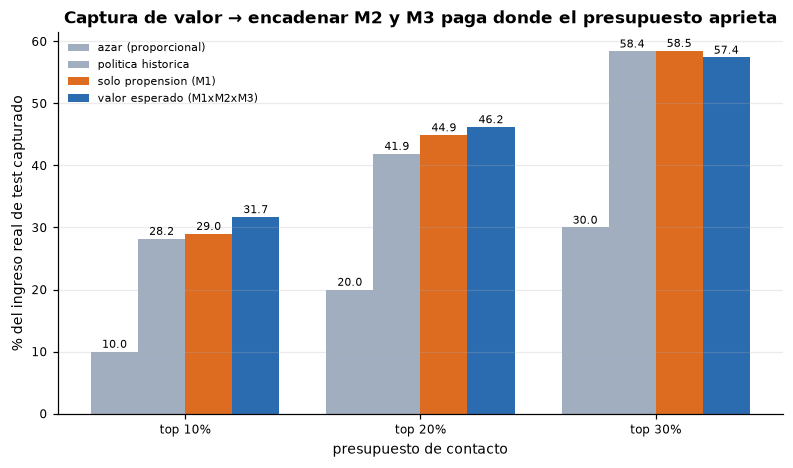

In [24]:
captura = mdl.value_capture(valores, X_test)
display(captura)
print(captura.attrs["lectura"])

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plots.plot_value_capture(captura, ax=ax)
plt.show()

**Consecuencia — esta es la respuesta a por qué tres modelos y no uno.** Con presupuesto para
contactar el **10%** de las visitas, medido contra el **ingreso realmente facturado** en test:

| Política | % del ingreso capturado | Lift |
|---|---|---|
| azar | 10.0% | ×1.00 |
| política histórica (tasa pasada) | 28.2% | ×2.82 |
| solo propensión (M1) | 29.0% | ×2.90 |
| **valor esperado (M1 × M2 × M3)** | **31.7%** | **×3.17** |

Encadenar M2 y M3 detrás de M1 añade **+2.7 puntos** de ingreso capturado sobre ordenar por
probabilidad de compra, y **+3.5** sobre la política vigente. Donde M1 solo ganaba 0.04 de lift
contando compradores, la cadena completa gana 3.5 puntos de ingreso: **ordenar por dinero no es lo
mismo que ordenar por probabilidad.**

Y el matiz que hay que decir: con presupuesto para el 30% la ventaja se diluye y la política
histórica iguala (58.4% vs 57.4%). La cadena paga **donde el presupuesto aprieta**, que es
precisamente el régimen en el que existe el problema de targeting. Si se puede contactar a todo el
mundo, no hace falta modelo.

---
## 8 · Congelar los resultados y cerrar la fase

In [25]:
resultados = {
    "m1": {
        "modelo": f"logistica C={mejor_C['C']}",
        "features": int(X_train.shape[1]),
        "pr_auc_test": float(m1_test["pr_auc"]),
        "roc_auc_test": float(m1_test["roc_auc"]),
        "brier": float(m1_test["brier"]),
        "lift_top10": float(contra_baseline.attrs["lift_modelo_top10"]),
        "lift_top10_politica_historica": float(contra_baseline.attrs["lift_baseline_top10"]),
        "pr_auc_cv_estricta": float(
            comparacion[
                (comparacion["modelo"] == "1 · logistica")
                & comparacion["esquema"].str.startswith("cliente nuevo")
            ]["pr_auc_media"].iloc[0]
        ),
    },
    "m2": {
        "modelo_prediccion": "random forest",
        "modelo_elasticidades": "logit multinomial sin penalizacion",
        "log_loss_test": float(m2_test["log_loss"]),
        "accuracy_test": float(m2_test["accuracy"]),
        "elasticidades_propias": elasticidades.attrs["elasticidades_propias"],
        "marcas_identificadas": diagnostico.attrs["marcas_identificadas"],
        "marcas_no_identificadas": diagnostico.attrs["marcas_no_identificadas"],
    },
    "m3": {
        "modelo": "poisson",
        "mae_test": float(m3_test["mae"]),
        "rmse_test": float(m3_test["rmse"]),
        "mae_baseline": float(m3_test["mae_baseline_media"]),
    },
    "umbral": {
        "regla": "umbral = costo de contacto / margen por compra",
        "desvio_maximo_verificado": float(regla.attrs["max_desvio"]),
        "contactos_en_0.5_pct": float(umbral.attrs["pct_en_0.5"]),
    },
    "captura_de_valor_top10_pct": {
        fila["politica"]: float(fila["pct_del_ingreso"])
        for _, fila in captura[captura["presupuesto"] == "top 10%"].iterrows()
    },
    "features_descartadas": mdl.TREND_COLS,
}
payload = mdl.freeze(resultados)
print("congelado en:", mdl.MODELS_PATH.relative_to(ROOT))
print(json.dumps(payload, indent=2, ensure_ascii=False)[:1200], "...")

congelado en: artifacts/modelos.json
{
  "fecha": "2026-11-19",
  "split_day": 550,
  "m1": {
    "modelo": "logistica C=0.03",
    "features": 59,
    "pr_auc_test": 0.4776,
    "roc_auc_test": 0.6931,
    "brier": 0.1671,
    "lift_top10": 2.5,
    "lift_top10_politica_historica": 2.46,
    "pr_auc_cv_estricta": 0.5273
  },
  "m2": {
    "modelo_prediccion": "random forest",
    "modelo_elasticidades": "logit multinomial sin penalizacion",
    "log_loss_test": 0.7418,
    "accuracy_test": 0.7822,
    "elasticidades_propias": {
      "1": -8.93,
      "2": -2.821,
      "3": 9.508,
      "4": -1.943,
      "5": -1.266
    },
    "marcas_identificadas": [
      1,
      2,
      4,
      5
    ],
    "marcas_no_identificadas": [
      3
    ]
  },
  "m3": {
    "modelo": "poisson",
    "mae_test": 0.979,
    "rmse_test": 1.3959,
    "mae_baseline": 1.1768
  },
  "umbral": {
    "regla": "umbral = costo de contacto / margen por compra",
    "desvio_maximo_verificado": 0.055,
    "contac

In [26]:
reporte = mdl.phase4_report(
    m1_test, lift, contra_baseline, umbral, regla, m2_test, diagnostico, m3_test, captura
)
display(reporte)
print(reporte.attrs["lectura"])
assert reporte.attrs["fase4_completa"], "La Fase 4 tiene requisitos sin cerrar"
print(f"\nnotebook completo en {time.time() - t_inicio:.0f}s")

,requisito,resultado,ok
0,S1 · M1 entrega pi_it,PR-AUC 0.4776 (azar 0.2480),True
1,S1 · M2 entrega q_ijt,accuracy 0.7822 vs clase mayoritaria 0.3407,True
2,S1 · M3 entrega lambda_ijt,MAE 0.9790 vs baseline de la media 1.1768,True
3,S3 · elasticidades cruzadas del logit,4 de 5 elasticidades propias identificadas,True
4,S5 · PR-AUC como metrica principal,accuracy reportada solo junto a su baseline (0...,True
5,S6 · umbral derivado del costo,"regla umbral=costo/margen validada, desvio max...",True
6,S8 · superar el baseline de targeting,lift top 10%: modelo x2.50 vs politica histori...,True
7,S9 · composicion pi x q x lambda x precio,captura el 31.7% del ingreso con el 10% de las...,True


8 de 8 requisitos de la Fase 4 cerrados con evidencia ejecutada.

notebook completo en 63s


---
## 9 · Síntesis de la Fase 4

| Modelo | Elegido | Test | Contra qué |
|---|---|---|---|
| **M1** `π_it` | logística `C=0.03`, 59 features | PR-AUC **0.4776** | azar 0.2480 |
| **M2** `q_ijt` | random forest | accuracy **0.7822** | clase mayoritaria 0.3407 |
| **M2** elasticidades | logit multinomial | 4 de 5 propias identificadas | la marca 3 no lo está |
| **M3** `λ_ijt` | Poisson | MAE **0.9790** | media 1.1768 (−16.8%) |
| **Cadena** | π × q × λ × precio | **31.7%** del ingreso con el 10% de las visitas | histórica 28.2%, azar 10% |

### Las cuatro conclusiones de esta fase

1. **La complejidad no paga en M1, pero sí en M2.** Bajo el esquema estricto los tres candidatos
   de M1 quedan dentro del ruido (0.50–0.54) y gana la logística; en M2 el random forest mejora el
   log-loss en 0.21 sobre el logit. La progresión del brief se recorrió y la respuesta fue distinta
   para cada modelo — que es la única razón por la que vale la pena recorrerla.

2. **`GroupKFold` no es el límite pesimista en un panel.** Para el random forest infla el PR-AUC en
   **0.24** frente a validar con cliente nuevo *y* día futuro, porque entrena con los mismos días.
   Es el error de validación más fácil de cometer aquí y el más difícil de detectar después.

3. **El umbral 0.5 cuesta dinero.** La regla `umbral = costo/margen` se verificó sobre test
   (desvío máximo 0.055). Con un ratio de 0.2 se contacta el 41.4% de las visitas y se capturan el
   63.1% de las compras; con 0.5, el 9.7% y el 24.5%.

4. **La cadena completa es lo que crea valor, no M1 solo.** M1 apenas bate la política histórica
   ordenando compradores (×2.50 vs ×2.46), pero ordenar por ingreso esperado captura **+3.5 puntos**
   del ingreso real con el mismo presupuesto. El trío de modelos no era elegancia arquitectónica:
   era la diferencia medible.

### Lo que esta fase deja declarado, no resuelto

- **La elasticidad propia de la marca 3 no está identificada** (positiva en las 5
  especificaciones). Tiene 21 puntos de precio, 14.4% de rango y 5.1% de las compras. P3 congela su
  precio o lo mueve dentro de un supuesto con sensibilidad; lo correcto es pedir un test A/B de
  precio.
- **Siguen faltando los costos** (`c_j`, `a`, `d_j`, `B`): el umbral y el valor esperado se
  entregan como función del ratio costo/margen y en unidades de ingreso, no de utilidad.

### Siguiente paso

**Fase 5** — pricing y captura de valor: elasticidades por segmento, curvas de propensión frente
al precio, los tres sub-problemas (P1 targeting, P2 calendario promocional, P3 pricing) resueltos
sobre estos parámetros, y los KPIs medidos contra grupo de control. Toda la evidencia que
necesitan ya está congelada en `artifacts/`.